# Final test: the locked 20%, used once

Every choice (model, hyperparameters, PD calibration, PD cutoff, rate model and inputs) was made in notebooks 02–09 using **only the 80% training set** (5-fold cross-validation). This notebook opens the **20% test set (6,482 applicants) for the first and only time** and scores those frozen choices. Nothing here is tuned or re-chosen, so these are the honest numbers for the report.

| Setting | Known when deciding | PD model (frozen) | Rate model (frozen) |
|---|---|---|---|
| Reference: already-priced loan | rate + grade | Random Forest (nb 05), isotonic calibration | none (rate already set) |
| Pipeline A: graded applicant | grade only | Random Forest (nb 08) | RF regressor on grade + details (nb 09) |
| Pipeline B: newcomer | neither | Random Forest (nb 06) | RF regressor on PD + details (nb 07) |

**Procedure for each setting**
1. Refit the chosen PD model on the **whole training set**.
2. Fit its calibration mapping (Platt or isotonic) on the model's **out-of-fold training scores** (saved by the earlier notebooks), exactly as chosen.
3. Score the test set: calibrated PD, then *default if PD ≥ the frozen cutoff*.
4. Refit the chosen rate model on all training loans with a known rate and predict the test applicants' rates. In Pipeline B the PD input on the test set is the newcomer PD from step 3 (as it would be for a real newcomer).
5. Report the metrics, a bootstrap 95% interval, the gap to validation, and an **error analysis**.

In [1]:
import sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score, roc_auc_score,
                             brier_score_loss, log_loss, confusion_matrix, mean_squared_error,
                             mean_absolute_error, r2_score)

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.credit import (RANDOM_STATE, DATA, REPORTS, TARGET, NUM_COLS, CAT_COLS, APPLICANT_NUM_COLS,
                        APPLICANT_CAT_COLS, load_train, make_pipeline, as_logit, ece, PD_EPS)

X_train, y_train = load_train()
test = pd.read_csv(DATA / "test.csv")                     # opened here for the first time
X_test, y_test = test.drop(columns=TARGET), test[TARGET]
print(f"train: {len(X_train):,} applicants   test: {len(X_test):,} applicants, default rate {y_test.mean():.4f}")

def load(name):
    return json.loads((REPORTS / name).read_text())

# ---- frozen choices from the earlier notebooks ----
rf_ref = load("random_forest_choice.json")["Random Forest"]
ref_summary = pd.read_csv(REPORTS / "pd_summary.csv", index_col=0)
ref_key = next(k for k in ref_summary.index if k.startswith("Random Forest"))
pdA, pdB = load("graded_pd_choice.json"), load("applicant_pd_choice.json")
rateA, rateB = load("rate_model_with_grade_choice.json"), load("rate_model_choice.json")

SETTINGS = {
    "Reference (rate + grade)": {
        "num": NUM_COLS, "cat": CAT_COLS, "params": rf_ref["params"], "calibration": ref_summary.loc[ref_key, "PD method"],
        "cutoff": float(ref_summary.loc[ref_key, "best PD cutoff"]), "oof_file": "oof_scores.npz",
        "oof_key": ref_key, "val_f1": float(ref_summary.loc[ref_key, "F1 @ best"]), "val_brier": float(ref_summary.loc[ref_key, "Brier"])},
    "Pipeline A (grade)": {
        "num": APPLICANT_NUM_COLS, "cat": APPLICANT_CAT_COLS + ["loan_grade"], "params": pdA["params"],
        "calibration": pdA["calibration"], "cutoff": pdA["pd_cutoff"], "oof_file": "oof_scores_graded.npz",
        "oof_key": None, "val_f1": pdA["cv_f1_at_cutoff"], "val_brier": pdA["brier"]},
    "Pipeline B (newcomer)": {
        "num": APPLICANT_NUM_COLS, "cat": APPLICANT_CAT_COLS, "params": pdB["params"],
        "calibration": pdB["calibration"], "cutoff": pdB["pd_cutoff"], "oof_file": "oof_scores_applicant.npz",
        "oof_key": None, "val_f1": pdB["cv_f1_at_cutoff"], "val_brier": pdB["brier"]},
}
for name, s in SETTINGS.items():
    if s["oof_key"] is None:     # the Random Forest's out-of-fold scores saved by notebooks 06 / 08
        s["oof_key"] = next(k for k in np.load(DATA / s["oof_file"]).files if k.startswith("Random Forest"))
    print(f"{name:<26} params {s['params']}, calibration {s['calibration']}, PD cutoff {s['cutoff']:.3f}")

train: 25,927 applicants   test: 6,482 applicants, default rate 0.2188
Reference (rate + grade)   params {'max_depth': 30, 'min_samples_leaf': 1, 'criterion': 'gini', 'max_features': 0.5}, calibration isotonic, PD cutoff 0.378
Pipeline A (grade)         params {'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 30, 'criterion': 'gini'}, calibration isotonic, PD cutoff 0.367
Pipeline B (newcomer)      params {'min_samples_leaf': 2, 'max_features': None, 'max_depth': None, 'criterion': 'gini'}, calibration Platt (sigmoid), PD cutoff 0.388


## Step 1: Probability of default on the test set

For each setting: refit the Random Forest on all training applicants, calibrate with the mapping fitted on its out-of-fold training scores, and score the test applicants. The **95% interval** comes from 1,000 bootstrap resamples of the test set (how much the score would move with a different sample of 6,482 applicants).

In [2]:
def calibrator(oof_score, y, how):
    # fit the score -> PD mapping on out-of-fold TRAINING scores only
    if how == "isotonic":
        m = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(oof_score, y)
        return lambda s: np.clip(m.predict(s), PD_EPS, 1 - PD_EPS)
    if how == "Platt (sigmoid)":
        m = LogisticRegression(C=1e6).fit(as_logit(oof_score, True).reshape(-1, 1), y)
        return lambda s: np.clip(m.predict_proba(as_logit(s, True).reshape(-1, 1))[:, 1], PD_EPS, 1 - PD_EPS)
    return lambda s: np.clip(s, PD_EPS, 1 - PD_EPS)          # raw

def clf_metrics(y, p, cut):
    pred = (p >= cut).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {"precision": precision_score(y, pred), "recall": recall_score(y, pred), "F1": f1_score(y, pred),
            "accuracy": accuracy_score(y, pred), "ROC-AUC": roc_auc_score(y, p), "Brier": brier_score_loss(y, p),
            "log loss": log_loss(y, p), "ECE": ece(p, y), "mean PD": p.mean(), "approved share": np.mean(p < cut),
            "TP": tp, "FN": fn, "FP": fp, "TN": tn}

def bootstrap_ci(y, p, cut, n=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed); y = np.asarray(y); f1s, briers = [], []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        f1s.append(f1_score(y[i], (p[i] >= cut).astype(int))); briers.append(brier_score_loss(y[i], p[i]))
    return np.percentile(f1s, [2.5, 97.5]), np.percentile(briers, [2.5, 97.5])

test_pd, pd_rows, fitted_pd = {}, [], {}
for name, s in SETTINGS.items():
    t0 = time.time()
    model = make_pipeline(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1, **s["params"]),
                          num_cols=s["num"], cat_cols=s["cat"]).fit(X_train, y_train)
    cal = calibrator(np.load(DATA / s["oof_file"])[s["oof_key"]], y_train, s["calibration"])
    p = cal(model.predict_proba(X_test)[:, 1])
    test_pd[name], fitted_pd[name] = p, (model, cal)
    m = clf_metrics(y_test, p, s["cutoff"])
    (f1_lo, f1_hi), (b_lo, b_hi) = bootstrap_ci(y_test, p, s["cutoff"])
    pd_rows.append({"setting": name, "PD cutoff": s["cutoff"], **m, "F1 95% CI": f"{f1_lo:.3f}-{f1_hi:.3f}",
                    "Brier 95% CI": f"{b_lo:.3f}-{b_hi:.3f}", "validation F1": s["val_f1"], "validation Brier": s["val_brier"]})
    print(f"{name:<26} done [{time.time() - t0:.0f}s]")

pd_test = pd.DataFrame(pd_rows).set_index("setting")
pd_test["F1 change vs validation"] = pd_test["F1"] - pd_test["validation F1"]
print("\nTEST SET: probability of default (frozen models, frozen cutoffs)")
display(pd_test[["PD cutoff", "precision", "recall", "F1", "F1 95% CI", "validation F1", "F1 change vs validation",
                 "accuracy", "ROC-AUC", "Brier", "Brier 95% CI", "validation Brier", "log loss", "ECE", "mean PD",
                 "approved share"]].round(4).T)
print(f"actual default rate in the test set: {y_test.mean():.4f}")

Reference (rate + grade)   done [10s]


Pipeline A (grade)         done [9s]


Pipeline B (newcomer)      done [11s]

TEST SET: probability of default (frozen models, frozen cutoffs)


setting,Reference (rate + grade),Pipeline A (grade),Pipeline B (newcomer)
PD cutoff,0.3784,0.3667,0.3883
precision,0.9532,0.9564,0.8197
recall,0.7475,0.7433,0.6093
F1,0.8379,0.8365,0.699
F1 95% CI,0.823-0.853,0.821-0.852,0.677-0.719
validation F1,0.8291,0.8269,0.6908
F1 change vs validation,0.0088,0.0096,0.0082
accuracy,0.9367,0.9364,0.8852
ROC-AUC,0.942,0.9389,0.8917
Brier,0.0521,0.0529,0.0858


actual default rate in the test set: 0.2188


## Step 2: Error analysis for default prediction

1. **Confusion matrices:** how many defaulters are caught or missed, and how many good customers are wrongly declined.
2. **Reliability diagrams on the test set:** does a PD of 0.3 still mean about 30% defaults on unseen applicants?
3. **Errors by segment:** missed-defaulter rate (1 − recall) and wrongly-declined rate (false positives among repayers) by home ownership, loan purpose, income band and grade, for the two pipelines that a lender would use for applicants.

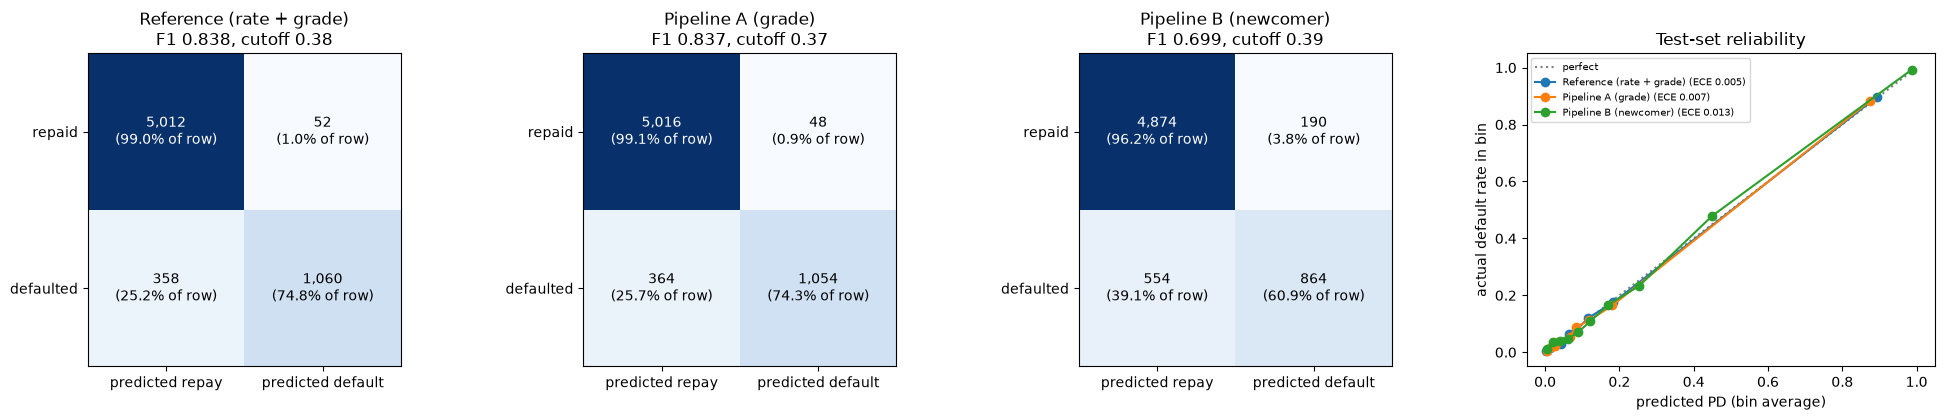

Errors by segment on the test set (missed defaulters = 1 - recall; declined = false-positive rate):


applicants  \
pipeline              segment               value                           
Pipeline A (grade)    person_home_ownership MORTGAGE                 2651   
                                            OTHER                      23   
                                            OWN                       533   
                                            RENT                     3275   
                      loan_intent           DEBTCONSOLIDATION        1010   
                                            EDUCATION                1239   
                                            HOMEIMPROVEMENT           733   
                                            MEDICAL                  1241   
                                            PERSONAL                 1085   
                                            VENTURE                  1174   
                      income band           lowest 25%               1636   
                                            25-50%                   1606   
                                            50-75%                   1676   
                                            highest 25%              1564   
                      loan-to-income        <=10%                    2090   
                                            10-20%                   2404   
                                            20-30%                   1221   
                                            >30%                      767   
                      loan_grade            A                        2172   
                                            B                        2103   
                                            C                        1215   
                                            D                         729   
                                            E                         208   
                                            F                          45   
                                            G                          10   
Pipeline B (newcomer) person_home_ownership MORTGAGE                 2651   
                                            OTHER                      23   
                                            OWN                       533   
                                            RENT                     3275   
                      loan_intent           DEBTCONSOLIDATION        1010   
                                            EDUCATION                1239   
                                            HOMEIMPROVEMENT           733   
                                            MEDICAL                  1241   
                                            PERSONAL                 1085   
                                            VENTURE                  1174   
                      income band           lowest 25%               1636   
                                            25-50%                   1606   
                                            50-75%                   1676   
                                            highest 25%              1564   
                      loan-to-income        <=10%                    2090   
                                            10-20%                   2404   
                                            20-30%                   1221   
                                            >30%                      767   
                      loan_grade            A                        2172   
                                            B                        2103   
                                            C                        1215   
                                            D                         729   
                                            E                         208   
                                            F                          45   
                                            G                          10   

                                                          

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.3))
for ax, (name, p) in zip(axes[:3], test_pd.items()):
    r = pd_test.loc[name]
    cm = np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({cm[i, j] / cm[i].sum():.1%} of row)", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=10)
    ax.set_xticks([0, 1], ["predicted repay", "predicted default"]); ax.set_yticks([0, 1], ["repaid", "defaulted"])
    ax.set_title(f"{name}\nF1 {r['F1']:.3f}, cutoff {r['PD cutoff']:.2f}")
ax = axes[3]
ax.plot([0, 1], [0, 1], color="grey", linestyle=":", label="perfect")
for name, p in test_pd.items():
    frac, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", label=f"{name} (ECE {pd_test.loc[name, 'ECE']:.3f})")
ax.set_xlabel("predicted PD (bin average)"); ax.set_ylabel("actual default rate in bin")
ax.set_title("Test-set reliability"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

# Errors by segment
seg = X_test.copy()
seg["defaulted"] = y_test.values
seg["income band"] = pd.qcut(seg["person_income"], 4, labels=["lowest 25%", "25-50%", "50-75%", "highest 25%"])
seg["loan-to-income"] = pd.cut(seg["loan_percent_income"], [-0.01, 0.1, 0.2, 0.3, 1.0],
                               labels=["<=10%", "10-20%", "20-30%", ">30%"])
rows = []
for name in ["Pipeline A (grade)", "Pipeline B (newcomer)"]:
    pred = test_pd[name] >= SETTINGS[name]["cutoff"]
    for col in ["person_home_ownership", "loan_intent", "income band", "loan-to-income", "loan_grade"]:
        for val, g in seg.assign(pred=pred).groupby(col, observed=True):
            d, r_ = g[g["defaulted"] == 1], g[g["defaulted"] == 0]
            rows.append({"pipeline": name, "segment": col, "value": val, "applicants": len(g),
                         "default rate": g["defaulted"].mean(),
                         "missed defaulters": 1 - d["pred"].mean() if len(d) else np.nan,
                         "good customers declined": r_["pred"].mean() if len(r_) else np.nan})
by_seg = pd.DataFrame(rows).set_index(["pipeline", "segment", "value"])
print("Errors by segment on the test set (missed defaulters = 1 - recall; declined = false-positive rate):")
display(by_seg.round(3))

## Step 3: Interest rate on the test set

The chosen rate model of each pipeline is refitted on **all training loans with a known rate** and predicts the test applicants' rates (test applicants without a recorded rate cannot be scored). The error is reported for all test loans and separately for **approved** applicants (PD below the cutoff), the only ones who would be offered a rate.

In [4]:
tr_known = X_train["loan_int_rate"].notna().to_numpy()
te_known = X_test["loan_int_rate"].notna().to_numpy()
oof_pd_B = pd.read_csv(DATA / "oof_pd_applicant.csv")["applicant_pd"].to_numpy()

rate_rows, rate_pred = [], {}
for name, choice in [("Pipeline A (grade)", rateA), ("Pipeline B (newcomer)", rateB)]:
    Xtr, Xte = X_train[tr_known].copy(), X_test[te_known].copy()
    if "applicant_pd" in choice["numeric"]:
        Xtr["applicant_pd"] = oof_pd_B[tr_known]                  # out-of-fold PD, as in notebook 07
        Xte["applicant_pd"] = test_pd["Pipeline B (newcomer)"][te_known]   # the newcomer PD the system would compute
    model = make_pipeline(RandomForestRegressor(n_estimators=choice["rf_n_estimators"], random_state=RANDOM_STATE,
                                                n_jobs=-1, **choice["rf_params"]),
                          num_cols=choice["numeric"], cat_cols=choice["categorical"])
    model.fit(Xtr, Xtr["loan_int_rate"])
    pred = model.predict(Xte)
    actual = Xte["loan_int_rate"].to_numpy()
    rate_pred[name] = (actual, pred, Xte)
    approved = test_pd[name][te_known] < SETTINGS[name]["cutoff"]
    for label, m in [("all test loans", np.ones(len(actual), bool)), ("approved (PD < cutoff)", approved),
                     ("declined", ~approved)]:
        rate_rows.append({"pipeline": name, "group": label, "loans": int(m.sum()),
                          "RMSE (pp)": np.sqrt(mean_squared_error(actual[m], pred[m])),
                          "MAE (pp)": mean_absolute_error(actual[m], pred[m]), "R²": r2_score(actual[m], pred[m]),
                          "validation RMSE": choice["cv_rmse"] if label == "all test loans" else np.nan,
                          "validation R²": choice["cv_r2"] if label == "all test loans" else np.nan})
rate_test = pd.DataFrame(rate_rows).set_index(["pipeline", "group"])
print(f"TEST SET: interest rate ({te_known.sum():,} of {len(X_test):,} test applicants have a recorded rate)")
display(rate_test.round(4))

TEST SET: interest rate (5,851 of 6,482 test applicants have a recorded rate)


loans  RMSE (pp)  MAE (pp)  \
pipeline              group                                                
Pipeline A (grade)    all test loans           5851     0.9872    0.7771   
                      approved (PD < cutoff)   4852     0.9804    0.7738   
                      declined                  999     1.0199    0.7934   
Pipeline B (newcomer) all test loans           5851     2.7033    2.1925   
                      approved (PD < cutoff)   4907     2.7256    2.2207   
                      declined                  944     2.5838    2.0456   

                                                  R²  validation RMSE  \
pipeline              group                                             
Pipeline A (grade)    all test loans          0.9073           0.9968   
                      approved (PD < cutoff)  0.8912              NaN   
                      declined                0.9067              NaN   
Pipeline B (newcomer) all test loans          0.3048           2.7022   
                      approved (PD < cutoff)  0.2628              NaN   
                      declined                0.3494              NaN   

                                              validation R²  
pipeline              group                                  
Pipeline A (grade)    all test loans                 0.9054  
                      approved (PD < cutoff)            NaN  
                      declined                          NaN  
Pipeline B (newcomer) all test loans                 0.3049  
                      approved (PD < cutoff)            NaN  
                      declined                          NaN

## Step 4: Error analysis for the interest rate

- **Predicted vs actual** for both pipelines.
- **Error by actual rate band:** where are rates over- or under-predicted?
- **Pipeline A: error within each grade.**

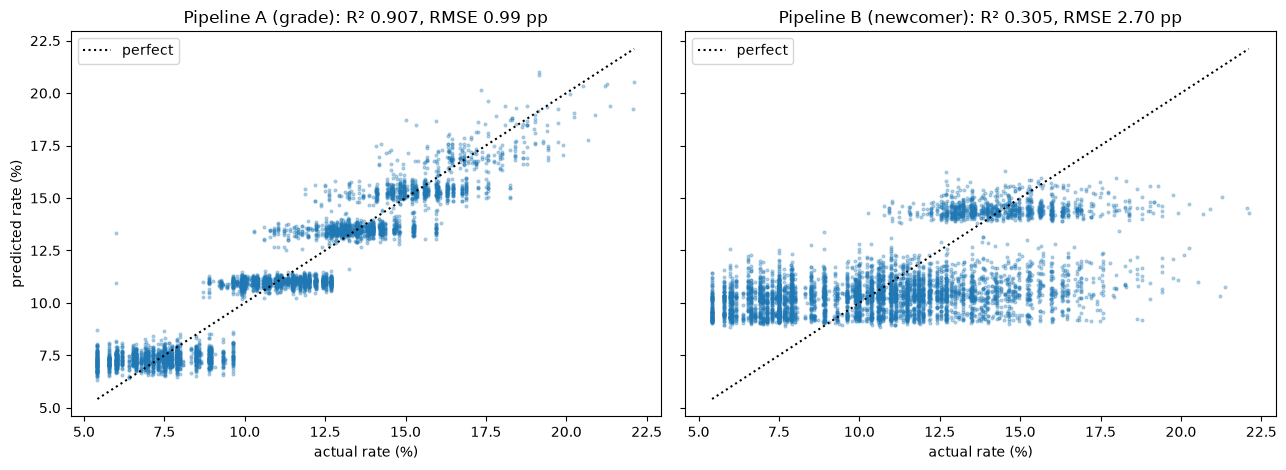

Rate error by actual rate band (positive mean error = over-predicted):


loans  mean error (pred - actual)  MAE (pp)
pipeline              actual rate                                             
Pipeline A (grade)    <8%           1641                       0.358     0.678
                      8-11%         1343                       0.135     0.886
                      11-14%        1786                      -0.182     0.727
                      14-17%         929                      -0.270     0.828
                      >17%           152                      -0.887     1.174
Pipeline B (newcomer) <8%           1641                       3.097     3.097
                      8-11%         1343                       0.371     0.878
                      11-14%        1786                      -1.087     1.763
                      14-17%         929                      -2.697     2.784
                      >17%           152                      -5.474     5.474

Pipeline A: rate error within each grade:


,loans,mean_error,MAE,RMSE
grade,,,,
A,1978,0.041,0.806,1.017
B,1886,-0.048,0.736,0.894
C,1091,0.041,0.722,0.976
D,666,0.020,0.840,1.075
E,182,0.018,0.916,1.168
F,40,0.090,1.050,1.371
G,8,0.341,1.246,1.504


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, (name, (actual, pred, Xte)) in zip(axes, rate_pred.items()):
    ax.scatter(actual, pred, s=4, alpha=0.3)
    lims = [actual.min(), actual.max()]
    ax.plot(lims, lims, color="black", linestyle=":", label="perfect")
    r = rate_test.loc[(name, "all test loans")]
    ax.set_title(f"{name}: R² {r['R²']:.3f}, RMSE {r['RMSE (pp)']:.2f} pp")
    ax.set_xlabel("actual rate (%)"); ax.legend()
axes[0].set_ylabel("predicted rate (%)")
plt.tight_layout(); plt.show()

band_rows = []
for name, (actual, pred, Xte) in rate_pred.items():
    bands = pd.cut(actual, [0, 8, 11, 14, 17, 25], labels=["<8%", "8-11%", "11-14%", "14-17%", ">17%"])
    for b in bands.categories:
        m = np.asarray(bands == b)
        band_rows.append({"pipeline": name, "actual rate": b, "loans": int(m.sum()),
                          "mean error (pred - actual)": np.mean(pred[m] - actual[m]),
                          "MAE (pp)": np.mean(np.abs(pred[m] - actual[m]))})
print("Rate error by actual rate band (positive mean error = over-predicted):")
display(pd.DataFrame(band_rows).set_index(["pipeline", "actual rate"]).round(3))

actual, pred, Xte = rate_pred["Pipeline A (grade)"]
by_grade = (pd.DataFrame({"grade": Xte["loan_grade"].values, "err": pred - actual})
              .groupby("grade")["err"].agg(loans="size", mean_error="mean", MAE=lambda e: np.abs(e).mean(),
                                          RMSE=lambda e: np.sqrt(np.mean(e ** 2))))
print("Pipeline A: rate error within each grade:")
display(by_grade.round(3))

## Step 5: Final headline (test set)

The numbers for the website: each setting's frozen PD and rate models on the test set, next to their validation scores.

In [6]:
final = pd.DataFrame({
    name: {"PD F1 (test)": pd_test.loc[name, "F1"], "PD F1 95% CI": pd_test.loc[name, "F1 95% CI"],
           "PD F1 (validation)": pd_test.loc[name, "validation F1"],
           "PD precision": pd_test.loc[name, "precision"], "PD recall": pd_test.loc[name, "recall"],
           "PD ROC-AUC": pd_test.loc[name, "ROC-AUC"], "PD Brier (test)": pd_test.loc[name, "Brier"],
           "PD Brier (validation)": pd_test.loc[name, "validation Brier"], "PD ECE": pd_test.loc[name, "ECE"],
           "approved share": pd_test.loc[name, "approved share"],
           "rate RMSE (test, pp)": rate_test.loc[(name, "all test loans"), "RMSE (pp)"] if name != "Reference (rate + grade)" else np.nan,
           "rate R² (test)": rate_test.loc[(name, "all test loans"), "R²"] if name != "Reference (rate + grade)" else np.nan,
           "rate R² (validation)": rate_test.loc[(name, "all test loans"), "validation R²"] if name != "Reference (rate + grade)" else np.nan}
    for name in SETTINGS})
display(final.map(lambda v: round(v, 4) if isinstance(v, (float, np.floating)) else v))

final.to_csv(REPORTS / "final_test_headline.csv")
pd_test.round(4).to_csv(REPORTS / "final_test_pd.csv")
rate_test.round(4).to_csv(REPORTS / "final_test_rate.csv")
by_seg.round(4).to_csv(REPORTS / "final_test_errors_by_segment.csv")
print("saved reports/final_test_headline.csv, final_test_pd.csv, final_test_rate.csv, final_test_errors_by_segment.csv")

,Reference (rate + grade),Pipeline A (grade),Pipeline B (newcomer)
PD F1 (test),0.8379,0.8365,0.699
PD F1 95% CI,0.823-0.853,0.821-0.852,0.677-0.719
PD F1 (validation),0.8291,0.8269,0.6908
PD precision,0.9532,0.9564,0.8197
PD recall,0.7475,0.7433,0.6093
PD ROC-AUC,0.942,0.9389,0.8917
PD Brier (test),0.0521,0.0529,0.0858
PD Brier (validation),0.0556,0.0564,0.0879
PD ECE,0.0049,0.0074,0.0128
approved share,0.8284,0.83,0.8374


saved reports/final_test_headline.csv, final_test_pd.csv, final_test_rate.csv, final_test_errors_by_segment.csv
